# 03 · Recuperación y búsqueda

**Objetivo:** comparar tres maneras de recuperar fragmentos —**BM25** (léxica),
**densa** (embeddings + FAISS) e **híbrida** (fusión RRF)— sobre un conjunto
pequeño de preguntas hechas a mano. Medimos *recall@k* y MRR. Al final,
opcionalmente, un *cross-encoder* reordena los candidatos.

BM25 puntúa por solapamiento de términos (con un ajuste por longitud y por
rareza de la palabra). Es excelente cuando la pregunta trae un identificador
literal (`ci-retencion.yml`, `southamerica-west1`, `/salud`). La búsqueda densa
gana cuando la pregunta **parafrasea**. La híbrida intenta quedarse con lo mejor
de las dos, fusionando rangos (Reciprocal Rank Fusion), no puntuaciones crudas,
porque un 12 de BM25 y un 0,42 de coseno no están en la misma escala.


In [1]:
from pathlib import Path
import os, sys, json, time, gc, textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "rag_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de RAG "
        "(src/rag_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from rag_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    modo_rapido,
    guardar_json,
    cargar_json,
    cargar_corpus,
    cargar_preguntas,
    fragmentar_documentos,
    resumen_fragmentos,
    Codificador,
    similitud_coseno,
    IndiceNumpy,
    IndiceFAISS,
    IndiceBM25,
    fusion_rrf,
    Reranker,
    evaluar_recuperacion,
    construir_mensajes,
    construir_contexto,
    GeneradorLocal,
    contiene_hechos,
    parece_abstencion,
    PipelineRAG,
    evaluar_fidelidad,
    MODELO_EMBEDDINGS_DEFECTO,
    MODELO_RERANKER_DEFECTO,
    MODELO_LLM_DEFECTO,
    MODELO_LLM_RESERVA,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
MODO_RAPIDO = modo_rapido(True)
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")
print(f"Modo rapido: {MODO_RAPIDO}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/rag/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raiz:        /workspace/rag
Dispositivo: cpu
Semilla:     42
Modo rapido: True


In [2]:
# --- Mandos de este cuaderno ---
MODELO_EMB = MODELO_EMBEDDINGS_DEFECTO
K = 5
K_RRF = 60          # constante típica de Reciprocal Rank Fusion
USAR_RERANKER = not MODO_RAPIDO   # el cross-encoder es opcional y está en inglés
print(f"k={K}  k_rrf={K_RRF}  reranker={USAR_RERANKER}")


k=5  k_rrf=60  reranker=False


## 1. Cargar el índice y las preguntas

Reutilizamos el índice del cuaderno 02. Si no estuviera, se puede reconstruir;
aquí lo damos por escrito en `modelos/`. El modelo de embeddings sí hay que
cargarlo: hace falta embeber **las preguntas**.


In [3]:
indice = IndiceFAISS.cargar(RUTAS["modelos"] / "indice_faiss")
fragmentos = indice.fragmentos
indice_bm25 = IndiceBM25(fragmentos)
codificador = Codificador(MODELO_EMB, dispositivo_destino=str(DEVICE))
preguntas = cargar_preguntas(RUTAS["datos"] / "preguntas.json")
preguntas_hecho = [p for p in preguntas if p.get("tipo") != "no_esta"]
print(f"Fragmentos: {len(fragmentos)}")
print(f"Preguntas: {len(preguntas)} (evaluables para recall: {len(preguntas_hecho)})")
pd.DataFrame(preguntas)[["id", "tipo", "pregunta"]].head(8)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Fragmentos: 77
Preguntas: 20 (evaluables para recall: 18)


/workspace/rag/src/rag_utils.py:594: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.dim = int(self.modelo.get_sentence_embedding_dimension())


,id,tipo,pregunta
0,q01,hecho,¿Cuál es la calificación mínima de aprobación ...
1,q02,hecho,¿Hasta qué hora y en qué canal se entrega el A...
2,q03,hecho,¿Cómo se llama la imagen Docker de la API de e...
3,q04,hecho,¿Qué ruta consulta el healthcheck de la imagen...
4,q05,hecho,¿Cuál es el tracking URI por defecto de MLflow...
5,q06,hecho,¿Qué alias se asigna en el Model Registry de M...
6,q07,hecho,"En el manifiesto de ejemplo de Kubernetes, ¿cu..."
7,q08,hecho,¿Cómo se llama el archivo del workflow de GitH...


## 2. Una pregunta, tres listas

Miramos de cerca una pregunta que se puede parafrasear y otra que trae un
identificador literal. Para cada una listamos el top-k de BM25, el denso y el
híbrido.


In [4]:
def buscar_denso(pregunta, k=K):
    qv = codificador.codificar([pregunta], progreso=False)[0]
    return indice.buscar(qv, k=k)

def buscar_bm25(pregunta, k=K):
    return indice_bm25.buscar(pregunta, k=k)

def buscar_hibrido(pregunta, k=K):
    # Un poco más de candidatos por lista, luego fusionamos.
    denso = buscar_denso(pregunta, k=max(k, 8))
    lex = buscar_bm25(pregunta, k=max(k, 8))
    return fusion_rrf([denso, lex], k=k, k_rrf=K_RRF)

def mostrar(pregunta, k=4):
    print("=" * 70)
    print(pregunta)
    for nombre, fn in [("BM25", buscar_bm25), ("denso", buscar_denso), ("hibrido", buscar_hibrido)]:
        hits = fn(pregunta, k=k)
        print(f"\n  {nombre}:")
        for r in hits:
            extracto = r.fragmento.texto.replace("\n", " ")[:110]
            print(f"    {r.rango}. {r.puntuacion:.3f}  {r.fragmento.id}  {extracto}...")

mostrar("¿Cuántos días de vacaciones tiene un empleado de NubeAndina?")
mostrar("¿Cómo se llama el archivo del workflow de GitHub Actions del curso?")


¿Cuántos días de vacaciones tiene un empleado de NubeAndina?

  BM25:
    1. 16.747  nubeandina-vacaciones-y-trabajo::#0  # NubeAndina: vacaciones, presencialidad y trabajo remoto  Política interna de la empresa ficticia NubeAndina ...
    2. 12.426  nubeandina-vacaciones-y-trabajo::#1  jornada completa tiene **22 días laborables** de vacaciones al año. A ellos se suman **3 días** de **«cierre a...
    3. 10.717  nubeandina-vacaciones-y-trabajo::#6  liente por más de dos noches recibe un día hábil de descanso al regreso, que no descuenta vacaciones. El viaje...
    4. 10.658  nubeandina-vacaciones-y-trabajo::#7  o con jornada reducida. Si un asistente afirma que NubeAndina ofrece 30 días de vacaciones, trabajo remoto ili...



  denso:
    1. 0.729  nubeandina-vacaciones-y-trabajo::#0  # NubeAndina: vacaciones, presencialidad y trabajo remoto  Política interna de la empresa ficticia NubeAndina ...
    2. 0.673  nubeandina-vacaciones-y-trabajo::#7  o con jornada reducida. Si un asistente afirma que NubeAndina ofrece 30 días de vacaciones, trabajo remoto ili...
    3. 0.666  nubeandina-vacaciones-y-trabajo::#6  liente por más de dos noches recibe un día hábil de descanso al regreso, que no descuenta vacaciones. El viaje...
    4. 0.656  nubeandina-vacaciones-y-trabajo::#2  más de cinco días laborables seguidos se solicitan con **15 días naturales** de antelación en el sistema inter...



  hibrido:
    1. 0.033  nubeandina-vacaciones-y-trabajo::#0  # NubeAndina: vacaciones, presencialidad y trabajo remoto  Política interna de la empresa ficticia NubeAndina ...
    2. 0.032  nubeandina-vacaciones-y-trabajo::#7  o con jornada reducida. Si un asistente afirma que NubeAndina ofrece 30 días de vacaciones, trabajo remoto ili...
    3. 0.032  nubeandina-vacaciones-y-trabajo::#6  liente por más de dos noches recibe un día hábil de descanso al regreso, que no descuenta vacaciones. El viaje...
    4. 0.032  nubeandina-vacaciones-y-trabajo::#1  jornada completa tiene **22 días laborables** de vacaciones al año. A ellos se suman **3 días** de **«cierre a...
¿Cómo se llama el archivo del workflow de GitHub Actions del curso?

  BM25:
    1. 19.412  guia-github-actions::#0  # GitHub Actions en el curso (CI de la API de retención)  Este documento fija el convenio de integración conti...
    2. 14.176  guia-github-actions::#2  en este curso. CI valida; el despliegue se discute aparte


  denso:
    1. 0.752  guia-github-actions::#0  # GitHub Actions en el curso (CI de la API de retención)  Este documento fija el convenio de integración conti...
    2. 0.598  curso-avance-3::#0  # Guía de entrega del Avance 3  El Avance 3 del curso *De Modelo a Producción* concentra el registro de experi...
    3. 0.561  curso-avance-3::#5  baseline` y `candidato`). 3. El *tracking URI* usado en el laboratorio, que por defecto es `http://127.0.0.1:5...
    4. 0.547  guia-github-actions::#1  o se llama **`ci-retencion.yml`** y vive en `.github/workflows/`. El nombre del workflow (campo `name`) es `CI...



  hibrido:
    1. 0.033  guia-github-actions::#0  # GitHub Actions en el curso (CI de la API de retención)  Este documento fija el convenio de integración conti...
    2. 0.032  curso-avance-3::#0  # Guía de entrega del Avance 3  El Avance 3 del curso *De Modelo a Producción* concentra el registro de experi...
    3. 0.032  guia-github-actions::#2  en este curso. CI valida; el despliegue se discute aparte y, si existe, es otro workflow.  ## Trabajos  El wor...
    4. 0.031  guia-github-actions::#1  o se llama **`ci-retencion.yml`** y vive en `.github/workflows/`. El nombre del workflow (campo `name`) es `CI...


## 3. Métricas: *recall@k* y MRR

*Recall@k* (aquí, con un conjunto de documentos relevantes por pregunta): vale 1
si **al menos un** documento de referencia aparece en los k primeros, 0 si no.
Es una medida de «¿cayó lo que buscábamos en la ventana que le vamos a dar al
LLM?».

**MRR** (*mean reciprocal rank*) es la media de 1/r, donde r es el rango
del primer documento relevante (y 0 si no aparece). Premia que lo bueno quede
arriba, no solo «en algún sitio del top-k».

El conjunto es pequeño y está hecho a mano: las cifras no son un *benchmark*
publicado, son una brújula para este laboratorio.


In [5]:
def evaluar(fn, nombre, k=K):
    res = evaluar_recuperacion(preguntas_hecho, fn, k=k, clave_oro="docs_relevantes", usar_doc_id=True)
    print(f"{nombre:10s}  recall@{k}={res[f'recall@{k}']:.3f}  MRR={res['mrr']:.3f}  n={res['n_evaluadas']}")
    return res

eval_bm25 = evaluar(buscar_bm25, "BM25")
eval_denso = evaluar(buscar_denso, "denso")
eval_hib = evaluar(buscar_hibrido, "hibrido")

tabla_met = pd.DataFrame([
    {"metodo": "BM25", f"recall@{K}": eval_bm25[f"recall@{K}"], "MRR": eval_bm25["mrr"]},
    {"metodo": "denso", f"recall@{K}": eval_denso[f"recall@{K}"], "MRR": eval_denso["mrr"]},
    {"metodo": "hibrido", f"recall@{K}": eval_hib[f"recall@{K}"], "MRR": eval_hib["mrr"]},
])
tabla_met


BM25        recall@5=1.000  MRR=0.963  n=18


denso       recall@5=1.000  MRR=0.907  n=18


hibrido     recall@5=1.000  MRR=0.963  n=18


,metodo,recall@5,MRR
0,BM25,1.0,0.962963
1,denso,1.0,0.907407
2,hibrido,1.0,0.962963


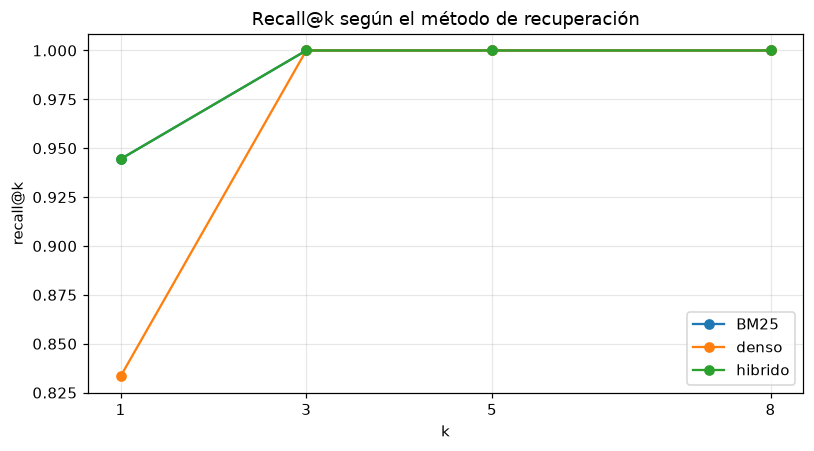

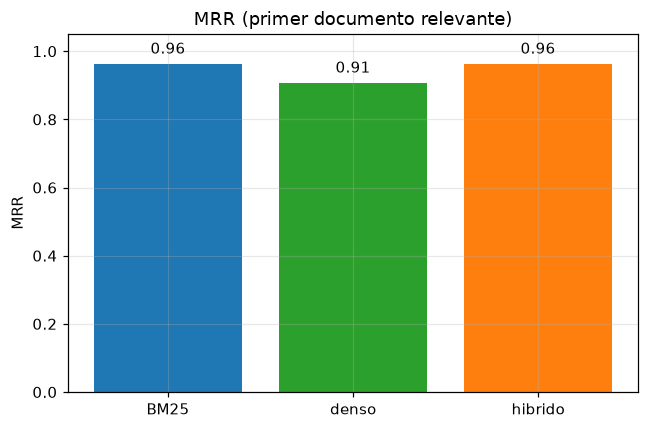

,k,metodo,recall,mrr
0,1,BM25,0.944444,0.944444
1,1,denso,0.833333,0.833333
2,1,hibrido,0.944444,0.944444
3,3,BM25,1.000000,0.962963
4,3,denso,1.000000,0.907407
5,3,hibrido,1.000000,0.962963
6,5,BM25,1.000000,0.962963
7,5,denso,1.000000,0.907407
8,5,hibrido,1.000000,0.962963
9,8,BM25,1.000000,0.962963


In [6]:
# recall@k para varios k, misma comparación
ks = [1, 3, 5, 8]
filas_k = []
for k in ks:
    for nombre, fn in [("BM25", buscar_bm25), ("denso", buscar_denso), ("hibrido", buscar_hibrido)]:
        r = evaluar_recuperacion(preguntas_hecho, fn, k=k, clave_oro="docs_relevantes")
        filas_k.append({"k": k, "metodo": nombre, "recall": r[f"recall@{k}"], "mrr": r["mrr"]})
tabla_k = pd.DataFrame(filas_k)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for nombre, sub in tabla_k.groupby("metodo"):
    ax.plot(sub["k"], sub["recall"], marker="o", label=nombre)
ax.set_xlabel("k")
ax.set_ylabel("recall@k")
ax.set_title("Recall@k según el método de recuperación")
ax.set_xticks(ks)
ax.legend()
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_recall_at_k.png", dpi=130)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4.0))
mrrs = tabla_met.set_index("metodo")["MRR"]
ax.bar(mrrs.index, mrrs.values, color=["#1f77b4", "#2ca02c", "#ff7f0e"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("MRR")
ax.set_title("MRR (primer documento relevante)")
for i, v in enumerate(mrrs.values):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center")
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_mrr.png", dpi=130)
plt.show()
tabla_k


## 4. Reordenar con un *cross-encoder* (opcional)

Un *bi-encoder* (el de embeddings) codifica la pregunta y el fragmento **por
separado**, y por eso puede indexar el corpus de antemano. Un *cross-encoder*
lee el par (pregunta, fragmento) junto y suele ordenar mejor, pero no escala a
todo el corpus: se aplica solo a los k candidatos ya recuperados.

El modelo por defecto, `cross-encoder/ms-marco-MiniLM-L-6-v2`, está entrenado
sobre MS MARCO (**inglés**). En un corpus en español puede ayudar un poco o no
ayudar nada: lo medimos, no lo damos por sentado. En modo rápido esta celda se
salta la descarga.


In [7]:
eval_rerank = None
reranker = None
if USAR_RERANKER:
    try:
        t0 = time.perf_counter()
        reranker = Reranker(MODELO_RERANKER_DEFECTO, dispositivo_destino=str(DEVICE))
        print(f"Reranker cargado en {time.perf_counter() - t0:.1f} s: {reranker.nombre}")

        def buscar_rerank(pregunta, k=K):
            cand = buscar_hibrido(pregunta, k=max(8, k))
            return reranker.reordenar(pregunta, cand, k=k)

        eval_rerank = evaluar(buscar_rerank, "hibrido+rerank")
    except Exception as exc:
        print(f"Reranker no disponible ({type(exc).__name__}: {exc}). Seguimos sin el.")
        reranker = None
else:
    print("Modo rapido: se omite el cross-encoder (USAR_RERANKER=False).")
    print("Pon USAR_RERANKER = True y reejecuta si quieres medirlo.")


Modo rapido: se omite el cross-encoder (USAR_RERANKER=False).
Pon USAR_RERANKER = True y reejecuta si quieres medirlo.


## 5. Dónde falla cada método

Una tabla con el primer documento recuperado ayuda a ver errores típicos: un
identificador literal que BM25 clava, o una paráfrasis que la densa entiende
mejor.


In [8]:
filas = []
for p in preguntas_hecho:
    oro = set(p.get("docs_relevantes") or [])
    recs = {
        "BM25": buscar_bm25(p["pregunta"], k=K),
        "denso": buscar_denso(p["pregunta"], k=K),
        "hibrido": buscar_hibrido(p["pregunta"], k=K),
    }
    fila = {"id": p["id"], "oro": ", ".join(sorted(oro)), "pregunta": p["pregunta"][:80]}
    for nombre, hits in recs.items():
        ids = [h.fragmento.doc_id for h in hits]
        fila[nombre + "_top"] = ids[0] if ids else ""
        fila[nombre + "_ok"] = any(i in oro for i in ids)
    filas.append(fila)
tabla_err = pd.DataFrame(filas)
# Preguntas donde los metodos no coinciden en el acierto
discrepan = tabla_err[
    tabla_err["BM25_ok"] != tabla_err["denso_ok"]
]
print("Preguntas en las que BM25 y la busqueda densa no coinciden en el acierto @k:")
if len(discrepan) == 0:
    print("  (ninguna en este conjunto; prueba a bajar k)")
else:
    print(discrepan[["id", "oro", "BM25_top", "BM25_ok", "denso_top", "denso_ok"]].to_string(index=False))
tabla_err[["id", "oro", "BM25_ok", "denso_ok", "hibrido_ok", "BM25_top", "denso_top"]]


Preguntas en las que BM25 y la busqueda densa no coinciden en el acierto @k:
  (ninguna en este conjunto; prueba a bajar k)


,id,oro,BM25_ok,denso_ok,hibrido_ok,BM25_top,denso_top
0,q01,curso-reglamento,True,True,True,curso-reglamento,curso-reglamento
1,q02,curso-avance-3,True,True,True,curso-avance-3,curso-avance-3
2,q03,guia-docker,True,True,True,guia-docker,guia-docker
3,q04,guia-docker,True,True,True,guia-docker,curso-avance-3
4,q05,guia-mlflow,True,True,True,curso-avance-3,curso-avance-3
5,q06,"curso-avance-3, guia-mlflow",True,True,True,curso-avance-3,guia-mlflow
6,q07,guia-kubernetes,True,True,True,guia-kubernetes,guia-kubernetes
7,q08,"curso-avance-3, guia-github-actions",True,True,True,guia-github-actions,guia-github-actions
8,q09,nubeandina-empresa,True,True,True,nubeandina-empresa,nubeandina-vacaciones-y-trabajo
9,q10,"nubeandina-datos-y-seguridad, nubeandina-empresa",True,True,True,nubeandina-empresa,nubeandina-empresa


In [9]:
payload = {
    "k": K,
    "n_preguntas": len(preguntas_hecho),
    "bm25": {"recall": eval_bm25[f"recall@{K}"], "mrr": eval_bm25["mrr"]},
    "denso": {"recall": eval_denso[f"recall@{K}"], "mrr": eval_denso["mrr"]},
    "hibrido": {"recall": eval_hib[f"recall@{K}"], "mrr": eval_hib["mrr"]},
    "rerank": (
        {"recall": eval_rerank[f"recall@{K}"], "mrr": eval_rerank["mrr"]}
        if eval_rerank is not None else None
    ),
    "recall_por_k": filas_k,
}
guardar_json(payload, RUTAS["resultados"] / "recuperacion.json")
print("Metricas escritas en resultados/recuperacion.json")
print("Siguiente cuaderno: 04-generacion-con-llm-local.")


Metricas escritas en resultados/recuperacion.json
Siguiente cuaderno: 04-generacion-con-llm-local.


## Recapitulando

- BM25 y la búsqueda densa se equivocan en sitios distintos: por eso se combinan.
- *Recall@k* responde «¿el contexto llegó al LLM?»; MRR, «¿qué tan arriba?».
- Un *reranker* es un lujo que se aplica a pocos candidatos, no al corpus entero.

Siguiente: [04-generacion-con-llm-local.ipynb](04-generacion-con-llm-local.ipynb).
